First five rows:
   fixed acidity  volatile acidity  citric acid  ...  sulphates  alcohol  quality
0            7.4              0.70         0.00  ...       0.56      9.4        5
1            7.8              0.88         0.00  ...       0.68      9.8        5
2            7.8              0.76         0.04  ...       0.65      9.8        5
3           11.2              0.28         0.56  ...       0.58      9.8        6
4            7.4              0.70         0.00  ...       0.56      9.4        5

[5 rows x 12 columns]

Dataset shape:
(1599, 12)

Column names:
Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality'],
      dtype='object')

Missing values:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
d

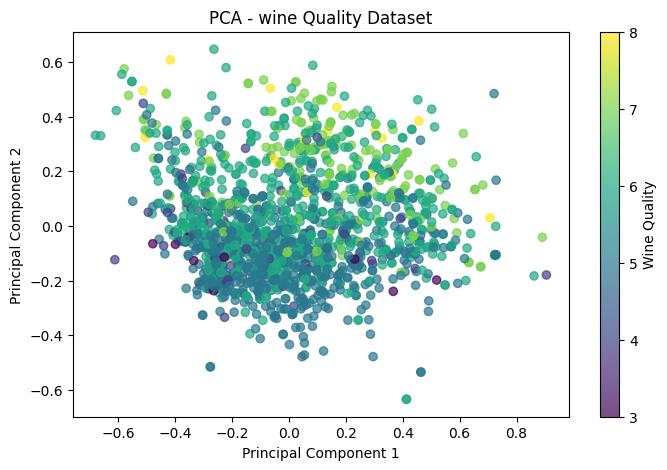

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA
df =pd.read_csv("winequality-red.csv")

print("First five rows:")
print(df.head())

print("\nDataset shape:")
print(df.shape)

print("\nColumn names:")
print(df.columns)

print("\nMissing values:")
print(df.isnull().sum())

x = df.drop('quality', axis=1)
y = df['quality']

normalizer = MinMaxScaler()
x_normalized = normalizer.fit_transform(x)

print("\nNormalized  data (first 5 rows):")
print(pd.DataFrame(
    x_normalized,
    columns=x.columns
).head().round(3))

standardizer = StandardScaler()
x_standardized = standardizer.fit_transform(x)

print("\nStandardized data (first 5 rows):")
print(pd.DataFrame(
    x_standardized,
    columns=x.columns
).head().round(3))

pca = PCA(n_components=2)
x_pca = pca.fit_transform(x_normalized)

print("\nPCA components (first 5 rows):")
print(pd.DataFrame(
    x_pca,
    columns=['PC1', 'PC2']
).head())

print("\nOriginal number of features:",x.shape[1])
print("Reduced number of features:",x_pca.shape[1])

print("Varience retained by each component:")
print(pca.explained_variance_ratio_.round(4))

print("Total variance retained:",round(sum(pca.explained_variance_ratio_)*100,2),"%")
plt.figure(figsize=(8,5))
plt.scatter(x_pca[:,0],x_pca[:,1],c=y,cmap="viridis",alpha=0.7)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA - wine Quality Dataset")
plt.colorbar(label="Wine Quality")
plt.show()